# Magnitudes & Colours


Observational data on galaxies very often comes in the form of magnitudes, a weird astronomical way of expressing the simple physical concept of flux. There is nothing important nor fundamental about magnitudes, but if you're in this business I'm afraid you gotta live with them... Let us thus learn how to convert a model spectrum $f_\lambda$ to AB magnitudes in different filters.

The first thing you need is a filter response curve $R_\lambda$, which tells what fraction of $\lambda$ photons you will actually detect when observing something with a given filter - the curve also includes the transmissivity of the atmosphere, telescope, etc. You'll see some real $R_\lambda$ curves soon. For now you can think of it as a top-hat function which is $= 0$ everywhere except between, say, $5500 < \lambda < 6500$ A.

When you observe a source whose spectrum is $f_\lambda$ through a filter $R_\lambda$ you'll measure some sort of __weigthed average__ of $f_\lambda$ within the $R_\lambda$ curve, which will then be turned onto a magnitude $m_{AB}$. The equations you need are


\begin{equation}
\label{eq:flambda_mAB}
\overline{f_\lambda} \equiv \frac{\int f_\lambda R_\lambda \lambda d\lambda}{\int R_\lambda \lambda  d\lambda} \end{equation}

which is the "sort of weigthed average" flux we mentioned above, and 


\begin{equation}
\lambda_\star^{-2} \equiv
\frac{\int \lambda^{-2} R_\lambda \lambda d\lambda}{ \int R_\lambda \lambda d\lambda}
\end{equation}

which defines the "Pivot wavelenth" of a filter (a funny kind of mean $\lambda$ over the $R_\lambda$ transmissivity curve). Finally, the corresponding magnitude in the AB system is 

\begin{equation}
m_{AB} = -2.5 \log \lambda_\star^2 \overline{f_\lambda} - 2.41
\end{equation}


for $\lambda$ in A and $f_\lambda$ in ergs$\,$s$^{-1}\,$cm$^{-2}\,$A$^{-1}$.


If these equations look odd to you it's because they are! Their strangeness is rooted in the use of $f_\nu$ (instead of $f_\lambda$) in the definition of AB magnitudes (see notes for details). In any case, these equations can be used both to compute $m_{AB}$ out of a spectrum $f_{\lambda}$, or in the opposite sense, i.e., to compute the $\overline{f_\lambda}$ corresponding to a given magnitude $m_{AB}$. 


<div class="alert alert-block alert-info">
<b>Here's an index of what you'll see in this notebook:</b> 
    
- **(Fig 1)** Plot a few famous broad band filters transmission curves $R_\lambda$ 
- **(Fig 2)** Pick an SSP, plot its $f_\lambda$ spectrum along with the corresponding photometric-fluxes $\overline{f_\lambda}$ in the same broad bands. You'll see the same thing in magnitudes (and hopefully realize that same things may look different!) 
- **(Fig 3)** Plot the "phometric-spectra" ($\overline{f_\lambda} \times \lambda$) of SPPs for a bunch of $\neq$ ages 
- **(Fig 4)** Plot the evolution of absolute magnitudes in several UV-optical bands and for different (initial) stellar masses 
- **(Fig 5)** Plot the colour evolution of SSPs for a bunch of colours
- **(Fig 6)** Inspect the evolution of SSPs in a colour-colour & colour magnitude diagrams

Most of these plots are analogous to the ones in a previous notebook. The main novelty here is that we are now talking about photometry in the way astronomers do, i.e., in terms of magnitudes.
</div>

## Initialization

In [12]:
# Initialization
%matplotlib inline
%matplotlib notebook
%matplotlib widget

import numpy as np
if not hasattr(np, "trapz"):
    np.trapz = np.trapezoid
import matplotlib.pyplot as plt
import cycler
from GeneralFunctionsLaPlata2024 import read_base_hdf5, read_filters_dict

# fontsize & etc...
_fs, _ls, _lw, _alpha = 20, 10, 2, 0.8

-------------------
#  Fig 1 - Plot some filter curves

The are tons of filters around, both broad (FWHM of order 1000 A) and narrow ($\sim 100$ A). The plot below shows 7 famous broad band filters in the UV-optical range. The code is not so tidy because of the way I read & define the filter curves, but it's readable if you're familiar with python-dictionary.


/tmp/ipykernel_480848/978691825.py:9: UserWarning: Ignoring specified arguments in this call because figure with num: 1 already exists
  figNum = 1 ; fig = plt.figure(figNum, figsize=(10, 6))


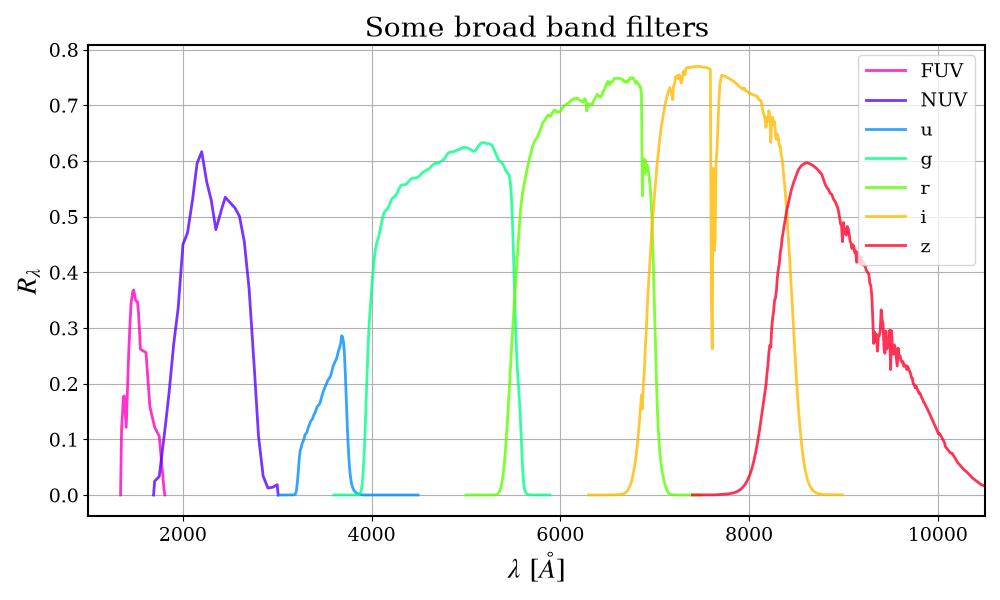

In [14]:
# read a few filter curves & plot them
# (apologies for convoluted way filters curves are stored...) 
filters = read_filters_dict(masterFiltDicFile='SPLUSFilters_ExtendedByErik.pkl')
filters_lab = list(filters.keys())
n_b = len(filters)

_color = plt.cm.gist_rainbow_r(np.linspace(0, 1, n_b))
plt.rcParams['axes.prop_cycle'] = cycler.cycler('color', _color)
figNum = 1 ; fig = plt.figure(figNum, figsize=(10, 6))
plt.clf()
for ib, i in enumerate(filters.keys()):
    plt.plot(filters[i]['curve']['wl'], filters[i]['curve']['transm'], alpha=_alpha, lw=_lw, label=filters_lab[ib])

plt.xlim(1000,10500)
plt.grid()
plt.legend()
plt.xlabel(r'$\lambda \,\, [\AA]$', fontsize=_fs)
plt.ylabel(r'$R_\lambda$', fontsize=_fs)
plt.title('Some broad band filters', fontsize=_fs)
plt.tight_layout()
plt.show()

### Questions:

- (1.1) Why is the amplitude (i.e. the scale) of these transmissivity curves not important? 
_(Tip: Have another look at the equations for $\overline{f_\lambda}$ and $\lambda_\star$.)_

- (1.2) Can you guess why some filters have "absorption-line" wiggles in their $R_\lambda$  profiles?

-------------------
# Fig 2 - Plot one SSP spectrum + photo-fluxes + filters

Let's compare a proper spectrum with it's coarser photometric representation. Let's use the SSP($\lambda; t, Z$) of the previous notebook for this exercise.

Set the metallicity (_Z4plot_, default = 0.02 = solar) and age (_t4plot_, between 1 Myr and 14 Gyr)of the SSP in the 1$^{st}$ lines of the cell. (You may also want to play with the redshiftm but don't go crazy!) If you want to plot results for a different $Z$, change _Z4plot_ to one of these values: 0.0001, 0.0004, 0.004, 0.008, 0.02, 0.05

(read_base_hdf5) reading  ./Base.bc03.Padova1994.chab.All.h5 ...
>>>SSP of age  1.01519 Gyr,   Z =  1.0  solar


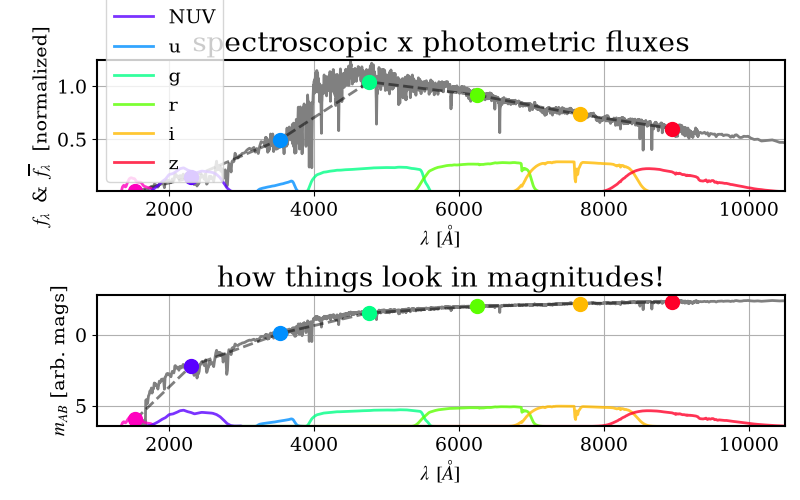

In [15]:
# Def age & Z for plot. Also, chose a redshift (keep it low!)
t4plot = 1.0e9
Z4plot = 0.02
redshift = 0.0

# Read the default base.<<<
basesDir = './'
baseFile = 'Base.bc03.Padova1994.chab.All'
t__j, _lix , Z__j, _lix, l__l, spec__lj = read_base_hdf5(basesDir + baseFile+'.h5')

# Pick the models for the chosen Z (default = solar) & closest in age to t4plot
m__j = (Z__j == Z4plot)
t__j, spec__lj = t__j[m__j], spec__lj[:,m__j]
logt__j = np.log10(t__j+1)
ind4plot = np.argwhere(np.abs(t__j - t4plot) == np.abs(t__j - t4plot).min())[0][0]
t4plot = t__j[ind4plot]
spec__l = spec__lj[:,ind4plot]

# Apply a redshift to the spectrum spec__l(l__l) - but only to wavelengths l__l!!
l__l *= (1 + redshift)

# Resample filter ib curve to l__l to facilitate the integrals ==> transm__lb
# Compute the photo-flux spec__b & the pivot wavelength l__b (the 1st two equations above)
n_l = len(l__l)
l__b, spec__b, transm__lb = np.zeros(n_b), np.zeros(n_b), np.zeros( (n_l,n_b) )
for ib, i in enumerate(filters.keys()):
    transm__lb[:,ib] = np.interp(l__l, filters[i]['curve']['wl'], filters[i]['curve']['transm'], left=0, right=0)
    r__l = transm__lb[:,ib] * l__l
    _den = np.trapezoid(r__l, x=l__l)
    spec__b[ib] = np.trapezoid(spec__l * r__l, x=l__l) / _den
    l__b[ib] = np.sqrt( 1 / ( np.trapezoid( (1 / l__l**2) * r__l, x=l__l) / _den ) )


# plot (normalized) spectrum & photo-fluxes + filter-curves
_color = plt.cm.gist_rainbow_r(np.linspace(0, 1, n_b))
plt.rcParams['axes.prop_cycle'] = cycler.cycler('color', _color)
figNum = 2 ; fig = plt.figure(figNum) #, figsize=(10, 8))
plt.clf()
fNorm = spec__l[np.abs(l__l - 5635) < 100].mean()
y = spec__l / fNorm
plt.subplot(211)
yLow, yUpp = 0.01, 1.2 * spec__b.max()/fNorm
plt.plot(l__l, y, color='gray')
plt.plot(l__b, spec__b/fNorm, 'k--', alpha=0.5)
for ib in range(n_b):
    plt.plot(l__l, 0.3*yUpp * transm__lb[:,ib], color=_color[ib], alpha=_alpha, lw=_lw, label=filters_lab[ib])
    plt.plot(l__b[ib], spec__b[ib]/fNorm, 'o', color=_color[ib], ms=10)

plt.xlim(1000,10500)
plt.ylim(yLow, yUpp)
plt.grid()
plt.legend()
plt.xlabel(r'$\lambda \,\, [\AA]$') #, fontsize=_fs)
plt.ylabel(r'$f_\lambda \,$ & $\, \overline{f_\lambda}$  [normalized]') #, fontsize=_fs)
plt.title('spectroscopic x photometric fluxes', fontsize=_fs)


# plot things in "relative magnitudes"
plt.subplot(212)
rel_mag__l = -2.5 * np.log10(l__l**2 * spec__l)
rel_mag__b = -2.5 * np.log10(l__b**2 * spec__b)
offset = rel_mag__b.mean()
rel_mag__l -= offset
rel_mag__b -= offset

yLow, yUpp = rel_mag__b.max() + 0.5, rel_mag__b.min() - 0.5
plt.plot(l__l, rel_mag__l, color='gray')
plt.plot(l__b, rel_mag__b, 'k--', alpha=0.5)
for ib in range(n_b):
    plt.plot(l__l, yLow - 0.2*(yLow-yUpp)*transm__lb[:,ib], color=_color[ib], alpha=_alpha, lw=_lw, label=filters_lab[ib])
    plt.plot(l__b[ib], rel_mag__b[ib], 'o', color=_color[ib], ms=10)

plt.xlim(1000,10500)
plt.ylim(yLow, yUpp)
plt.grid()
plt.xlabel(r'$\lambda \,\, [\AA]$') #, fontsize=_fs)
plt.ylabel(r'$m_{AB}$ [arb. mags]') #, fontsize=_fs)
plt.title('how things look in magnitudes!', fontsize=_fs)
plt.tight_layout()
print('>>>SSP of age ', t4plot/1e9, 'Gyr,   Z = ', Z4plot/0.02, ' solar')
plt.show()

In [16]:
# List fluxes (in arbitrary units) & magnitudes for all filters 
for ib in range(n_b):
    print(filters_lab[ib], l__b[ib], spec__b[ib]/fNorm, rel_mag__b[ib])

FUV 1535.0611173931652 0.009889643639151015 5.9643484641191264
NUV 2300.6558011921957 0.13992494713663434 2.2089323025443663
u 3533.296642640087 0.4974462099369561 -0.09983739232685718
g 4758.487870488028 1.0405602830396605 -1.5475845193874784
r 6251.830980205281 0.9151886510613273 -2.0008842789672157
i 7670.614529217762 0.7330706569570243 -2.2040869567506514
z 8942.792243885035 0.6005928194807632 -2.320887619231285


<div class="alert alert-block alert-info">
The top panel show spectroscopic (gray line, $f_\lambda$) & photometric (coloured circles, $\overline{f_\lambda}$) fluxes, while the bottom panel shows how things look in magnitudes. Both are in arbitrary units.
</div>


### Questions:

- (2.1) Repeat the plot for different ages (say, _t4plot = 1e6, 1e7, ..._).

- (2.2) Sometimes the photometric flux $\overline{f_\lambda}$ (the filled circles) does not fall on top of the actual spectrum $f_\lambda$ (gray line). Check, for instance, the g-band for _t4plot_ = 1 Gyr. Why? 

- (2.3) Comparing the top & bottom panels,  spectra plotted in AB magnitudes often convey the (wrong) impression that they are redder than the same spectrum plotted in fluxes. Any idea why?
_(Tip: Have another look at the equation for $m_{AB}$._)

-------------------
#  Fig 3 - Plot photo-spectra for some selected ages

In the previous notebook we plotted SSP spectra of different ages. When all you have is photometry (instead of full $\lambda$-by-$\lambda$ spectroscopy) __a lot__ of information is lost, but not all. The plot below shows how Fig 1 in the previous notebook would look if all you have is GALEX (FUC & NUV) and SDSS (ugriz) photometry.



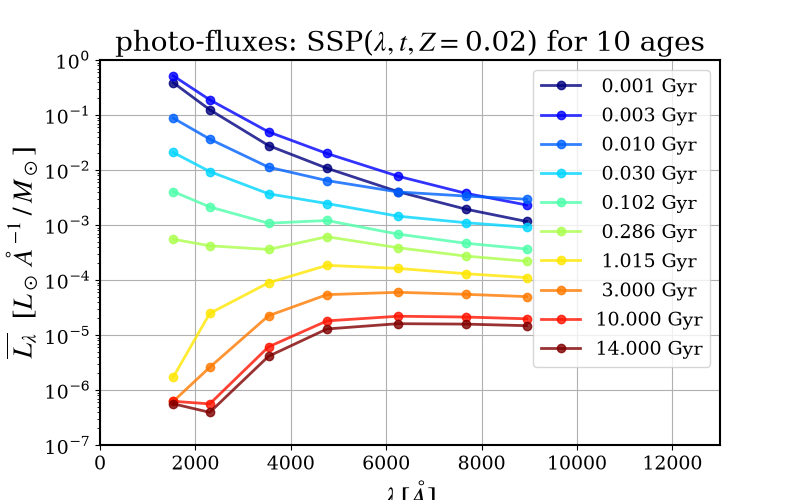

In [17]:
# compute synthetic photo-fluxes for SSPs of all ages
n_t = len(t__j)
spec__bj = np.zeros( (n_b, n_t) )
for ib, i in enumerate(filters.keys()):
    r__l = transm__lb[:,ib] * l__l
    _den = np.trapz(r__l)
    for j in range(n_t):
        spec__bj[ib,j] = np.trapz(spec__lj[:,j] * r__l) / _den

# convert model Lsun/A to a flux at 10pc in units of erg/s/cm2/A  (all per Msun!)
l2f_at_10pc = 3.826e33 / (4 * np.pi * (10 * 3.086e18)**2)
flux__lj = spec__lj * l2f_at_10pc
flux__bj = spec__bj * l2f_at_10pc

# Absolute AB mag (for 1 Msun!)
mag__bj = -2.5 * np.log10((l__b**2 * flux__bj.T).T) - 2.41


# Select ages to plot & match them to those in the base
_tList = np.array([1e6, 3e6, 1e7, 3e7, 1e8, 3e8, 1e9, 3e9, 1e10, 1.4e10])
_tListInBase = np.array([t__j[np.argmin(np.abs(t__j - _t))] for _t in _tList])

# set color cycle for different ages
_n_colors = np.unique(_tListInBase).size
_color = plt.cm.jet(np.linspace(0, 1, _n_colors))
plt.rcParams['axes.prop_cycle'] = cycler.cycler('color', _color)

# the plot
figNum = 3 ; fig = plt.figure(figNum)
plt.clf()
xLow, xUpp = 0, 12999
yLow, yUpp = 1e-7, 1
_fs, _lw, _alpha = 10, 2, 0.8
for _j in range(len(_tListInBase)):
    plt.plot(l__b,spec__bj[:,t__j == _tListInBase[_j]], 'o-',alpha=_alpha, lw=_lw, \
        label=str(f'{_tListInBase[_j]/1e9:6.3f}')+' Gyr')

plt.xlim(xLow,xUpp)
plt.ylim(yLow,yUpp)
plt.yscale('log')
plt.xlabel(r'$\lambda\,[\AA]$', fontsize=2*_fs)
plt.ylabel(r'$\overline{L_\lambda} \,\,\, [L_\odot \,\AA^{-1} \, / \, M_\odot]$', fontsize=2*_fs)
plt.grid(True)
plt.title(r'photo-fluxes: SSP($\lambda, t, Z=$' + str(Z4plot) + ') for ' + str(len(_tListInBase)) + ' ages', fontsize=2*_fs)
if len(_tListInBase) < 20:
    plt.legend(loc=1)
_fs, _ls, _lw, _alpha = 20, 10, 2, 0.8
plt.show()

### Questions:

- (3.1) Compare the photo-spectra in this plot with the full spectra in Fig 1 of the previous notebook.

- (3.2) Ask your stellar evolution teacher what causes the change of slope in the UV at very late ages! 

------
# Fig 4 - Now in absolute magnitudes...

Let's repeat the plot above, but now in absolute magnitudes.
To do this we have to do two things: 
- (1) Get rid of the "per $M_\odot$" in $\overline{L_\lambda}$ by multiplying it by a given galaxy mass $M_\star$ of your choice (defautlt _Mass_ = 1e10 $M_\odot$).
- (2) Convert luminosities to fluxes $\overline{f_\lambda} = \overline{L_\lambda} / 4 \pi d^2$ of a source at a distance of $d = 10$ pc. (This step also involves converting $L_\odot$ to erg/s and pc to cm). 

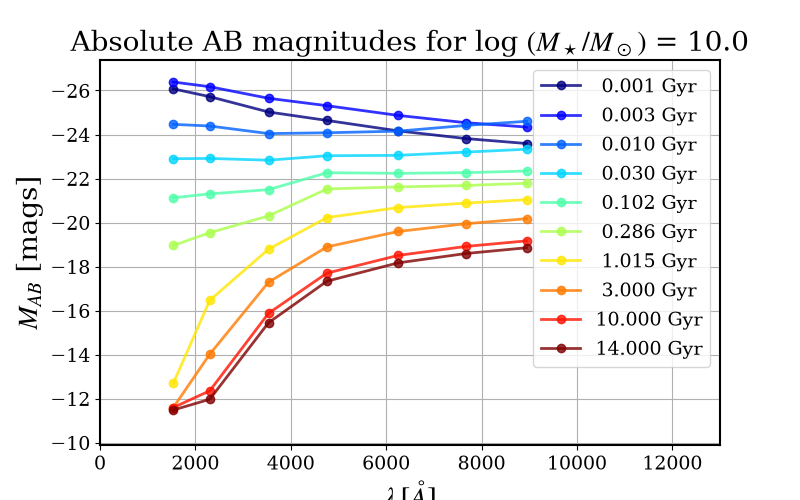

In [18]:
# Set galaxy mass (in solar masses) & adjust absolute magnitude for the given mass 
Mass = 1e10
Mag__bj = mag__bj - 2.5 * np.log10(Mass)

# set color cycle for different ages
_n_colors = np.unique(_tListInBase).size
_color = plt.cm.jet(np.linspace(0, 1, _n_colors))
plt.rcParams['axes.prop_cycle'] = cycler.cycler('color', _color)

# the plot
figNum = 4 ; fig = plt.figure(figNum)
plt.clf()
xLow, xUpp = 0, 12999
yLow, yUpp = Mag__bj.max() + 1, Mag__bj.min() - 1
_fs, _lw, _alpha = 10, 2, 0.8
for _j in range(len(_tListInBase)):
    plt.plot(l__b,Mag__bj[:,t__j == _tListInBase[_j]], 'o-',alpha=_alpha, lw=_lw, \
        label=str(f'{_tListInBase[_j]/1e9:6.3f}')+' Gyr')

plt.xlim(xLow,xUpp)
plt.ylim(yLow,yUpp)
plt.xlabel(r'$\lambda\,[\AA]$', fontsize=2*_fs)
plt.ylabel(r'$M_{AB}$ [mags]', fontsize=2*_fs)
plt.grid(True)
plt.title(r'Absolute AB magnitudes for log $(M_\star/M_\odot)$ = ' + str(np.log10(Mass)), fontsize=2*_fs)
if len(_tListInBase) < 20:
    plt.legend(loc=1)
_fs, _ls, _lw, _alpha = 20, 10, 2, 0.8
plt.show()

### Questions:

- (4.1) What will be the change in absolute magnitude if you multiply the system's mass by 10?
- (4.2) What will be the change in apparent magnitude if you multiply the system's mass by 10?

-------------------
# Fig 5 - Evolution (in mags!) @ some selected bands

The plots above all have $\lambda$ in the $x$-axis. To see how things change with time, it is instructive to plot things as a functon of $t$. The cell below plots the __absolute AB magnitude__ in our 7 UV-optical bands as a function of $\log t$. 

All previous SSP plots were done for an SSP of $1 M_\odot$ (a convenient normalization). In order to make things more galaxy-like let us now specify the (initial) stellar mass. That's what the _Mass = 1e11_ line does. 

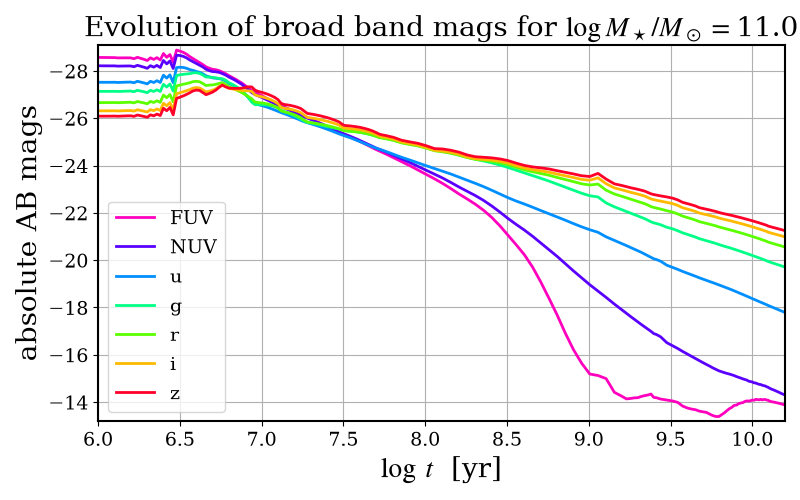

In [19]:
# Chose the stellar mass (affects the y-axis by -2.5 log M/Msun)
Mass = 1e11
log_Mass = np.log10(Mass)

# scale mag__bj to the desired mass
Mag__bj = mag__bj - 2.5 * log_Mass

# plot
_color = plt.cm.gist_rainbow_r(np.linspace(0, 1, n_b))
plt.rcParams['axes.prop_cycle'] = cycler.cycler('color', _color)
figNum = 5 ; fig = plt.figure(figNum)
plt.clf()
plt.plot(logt__j, Mag__bj.T, label=filters_lab)
plt.ylim(Mag__bj.max()+0.2, Mag__bj.min()-0.2)
plt.xlim(6,10.2)
plt.grid()
plt.legend()
plt.xlabel(r'$\log \, t \,\,$ [yr]', fontsize=_fs)
plt.ylabel(r'absolute AB mags', fontsize=_fs)
plt.title(r'Evolution of broad band mags for $\log M_\star/M_\odot =$' + str(log_Mass), fontsize=_fs)
plt.tight_layout()
plt.show()

### Questions:

- (5.1) Compare this plot with that in the previous notebook, where instead of photometric bands we plotted the evolution of $L_\lambda$ at specific $\lambda$'s. Except for the (damned!) $-2.5 \times$ in the definition of magnitudes, things should look similar!

- (5.2) Re-run the cell changing _Mass_ to values like $10^{9, 10, 11, 12} M_\odot$. Make sure you undestand why _log_Mass_ simply adds $-2.5 \log (M_\star/M_\odot)$ to the curve for a (obviously hypothetical) $M_\star = 1 M_\odot$ galaxy. 

- (5.3) By how many mags does an SSP dimms from $t = 1$ Myr to $t = 10$ Gyr in the 7 bands shown?

- (5.4) Does your answer to the previous question depend on $M_\star$?

- (5.5) Why do redder bands (say, z) change more than bluer ones (say, u or NUV)?

---------
# Fig 6 - Colour evolution


Let's now define a colour $m_1 - m_2$ and plot its time evolution for our SSP models. 
Chose the bands 1 & 2 yourself seting the variables b1 & b2 in the cell below. 
Possible choices for b1 & b2 are 'FUV', 'NUV', 'u', 'g', 'r', 'i', 'z'. Combine these as you wish, but remember that well behaved astronomers respect the convention that $\lambda_1 < \lambda_2$.

<div class="alert alert-block alert-success">
<b>Note:</b> When we first played with SSP spectra we defined colours as ratios of fluxes in arbitrary bands. That was just to introduce ideas. Here we'll compute colours as astronomers do, i.e., differences of magnitudes.
</div>

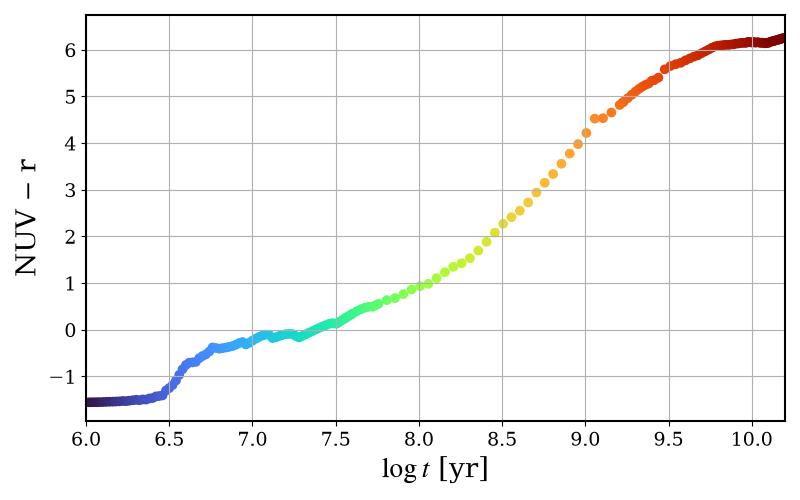

In [20]:
# Chose which color to show. Options for b1 & b2 are 'FUV', 'NUV', 'u', 'g', 'r', 'i', 'z'
b1 = 'NUV' ; b2 = 'r'

# id bands in filters_lab & compute color
ib1 = np.argwhere(np.array(filters_lab) == b1)[0][0]
ib2 = np.argwhere(np.array(filters_lab) == b2)[0][0]
x = mag__bj[ib1] - mag__bj[ib2] ; xLab = b1 + r' $-$ ' + b2

# the plot
_color = plt.cm.gist_rainbow_r(np.linspace(0, 1, n_t))
plt.rcParams['axes.prop_cycle'] = cycler.cycler('color', _color)
figNum = 6 ; fig = plt.figure(figNum)
plt.clf()
plt.scatter(logt__j, x, c=logt__j, cmap='turbo', vmin=6, vmax=10.15)
plt.xlim(6,10.2)
plt.grid()
plt.xlabel(r'$\log t$ [yr]', fontsize=_fs)
plt.ylabel(xLab, fontsize=_fs)
plt.tight_layout()
plt.show()

### Questions:

- (6.1) Do the plot for several colors, like NUV - r, g - r, u - r, FUV - NUV, g - i, etc...
- (6.2) Which colour gives the best age indicator in your opinion? Why?

---------
# Fig 7 - Evolution in color-color & color-magnitude diagrams


Let's now see how our SSPs evolve in a colour-colour diagram and in a colour-magnitude diagram (CMD). 
Unlike Figs 4 & 5, which involve a theroretical axis (the age), these two diagrams involve only observationally accessible quantities.


Chose four bands b1, b2, b3 & b4 in the cell below. (Remember, choices are 'FUV', 'NUV', 'u', 'g', 'r', 'i', 'z'). 

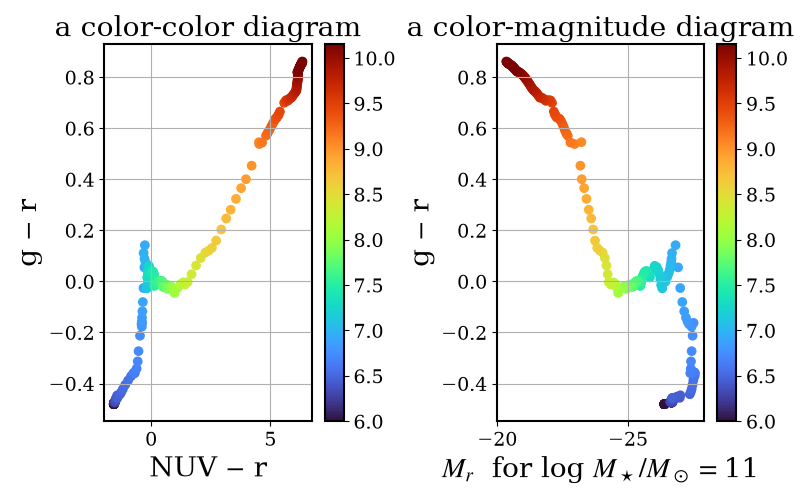

In [21]:
# Chose which colors to show: b1 - b2  X  b3 - b4
b1 = 'NUV' ; b2 = 'r'   ; b3 = 'g' ; b4 = 'r'

# Chose the stellar mass (affects only the x-axis of the CMD panel)
log_Mass = 11

# chose band for absolute magnitude axis in CMD 
band4xaxis_inCMD = 'r'

# id bands in filters_lab & compute colors
ib1 = np.argwhere(np.array(filters_lab) == b1)[0][0]
ib2 = np.argwhere(np.array(filters_lab) == b2)[0][0]
ib3 = np.argwhere(np.array(filters_lab) == b3)[0][0]
ib4 = np.argwhere(np.array(filters_lab) == b4)[0][0]
x = mag__bj[ib1] - mag__bj[ib2] ; xLab = b1 + r' $-$ ' + b2
y = mag__bj[ib3] - mag__bj[ib4] ; yLab = b3 + r' $-$ ' + b4

# the plot
_color = plt.cm.gist_rainbow_r(np.linspace(0, 1, n_t))
plt.rcParams['axes.prop_cycle'] = cycler.cycler('color', _color)
figNum = 7 ; fig = plt.figure(figNum)
plt.clf()

plt.subplot(121)
plt.scatter(x, y, c=logt__j, cmap='turbo', vmin=6, vmax=10.15) ; plt.colorbar()
plt.grid()
plt.xlabel(xLab, fontsize=_fs)
plt.ylabel(yLab, fontsize=_fs)
plt.title('a color-color diagram', fontsize=_fs)

ax2 = plt.subplot(122)
ib0 = np.argwhere(np.array(filters_lab) == band4xaxis_inCMD)[0][0]
x = mag__bj[ib0] - 2.5 * log_Mass
plt.scatter(x, y, c=logt__j, cmap='turbo', vmin=6, vmax=10.15) ; plt.colorbar()
plt.grid()
plt.xlabel(r'$M_r$  for log $M_\star/M_\odot =$' + str(log_Mass), fontsize=_fs)
plt.ylabel(yLab, fontsize=_fs)
plt.title('a color-magnitude diagram', fontsize=_fs)
ax2.invert_xaxis()
plt.tight_layout()

The color bar maps $\log t$/yr. 

### Questions: 

- (7.1) What is your favourite combination of filters and why?

- (7.2) What is the effect of the stellar (_log_Mass_) in these diagrams?

- (7.3) To undesrtand the crazy dance of the colours at young ages remember the zig-zags of evolutionary tracks for massive stars in their late phases...

The CMD is also used in stellar astronomy. In fact, it is nothing less than the Hertzsprung-Russell diagram itself, except that the x-y axis are mixed-up. But is the CMD above (ie., for an SSP) really comparable to the HR diagram of stars? It's a tricky question $\ldots$ just think about it.